<a href="https://colab.research.google.com/github/Hackathon-D-Group-2026/Hackathon_D_Group_2026/blob/main/Hackathon%20average%20hospitilazed%20cost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# --- Basic tools ---
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Splitting and fair testing ---
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score, GridSearchCV

# --- Pre-processing ---
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer                    # UNIVARIATE imputation
from sklearn.experimental import enable_iterative_imputer   # switches MICE on
from sklearn.impute import IterativeImputer                 # MULTIVARIATE imputation (MICE)

# --- The 5 machine-learning algorithms ---
from sklearn.linear_model import LogisticRegression     # 1
from sklearn.neighbors import KNeighborsClassifier      # 2
from sklearn.tree import DecisionTreeClassifier         # 3
from sklearn.ensemble import RandomForestClassifier     # 4
from xgboost import XGBClassifier                       # 5

# --- Measuring performance ---
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
TRAIN_FILE = "dataset_A_training.csv"
TEST_FILE = "dataset_A_testing.csv"   # the hackathon test file (no answers in it)

if not (os.path.exists(TRAIN_FILE) and os.path.exists(TEST_FILE)):
    try:
        from google.colab import files       # only works in Colab
        print("Please upload BOTH files:", TRAIN_FILE, "and", TEST_FILE)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {TRAIN_FILE} and {TEST_FILE} in the same folder as this notebook.")

df = pd.read_csv(TRAIN_FILE)
print("Training file - rows and columns:", df.shape)
if os.path.exists(TEST_FILE):
    print("Test file     - rows and columns:", pd.read_csv(TEST_FILE).shape, "(no seasonal_vaccine column)")
df.head()

Please upload BOTH files: dataset_A_training.csv and dataset_A_testing.csv


Saving dataset_A_training.csv to dataset_A_training.csv
Saving dataset_A_testing.csv to dataset_A_testing.csv
Saving dataset_A_example_submission.csv to dataset_A_example_submission.csv
Training file - rows and columns: (4756, 31)
Test file     - rows and columns: (4749, 30) (no seasonal_vaccine column)


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


In [3]:
TARGET = 'seasonal_vaccine'

train_df, test_df = train_test_split(df, test_size=0.15, random_state=RANDOM_STATE,
                                     stratify=df[TARGET])

print("Training people:", len(train_df))
print("Unseen test people:", len(test_df))

Training people: 4042
Unseen test people: 714


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4042 entries, 4659 to 1702
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4042 non-null   int64  
 1   flu_concern                    4032 non-null   float64
 2   flu_knowledge                  4020 non-null   float64
 3   behavioral_antiviral_meds      4029 non-null   float64
 4   behavioral_avoidance           4012 non-null   float64
 5   behavioral_face_mask           4039 non-null   float64
 6   behavioral_wash_hands          4036 non-null   float64
 7   behavioral_large_gatherings    4034 non-null   float64
 8   behavioral_outside_home        4034 non-null   float64
 9   behavioral_touch_face          4029 non-null   float64
 10  doctor_recc_seasonal           3766 non-null   float64
 11  child_under_6_months           3910 non-null   float64
 12  health_worker                  3911 non-null   flo

seasonal_vaccine
1    2168
0    1874
Name: count, dtype: int64

seasonal_vaccine
1    53.6 %
0    46.4 %
Name: proportion, dtype: object


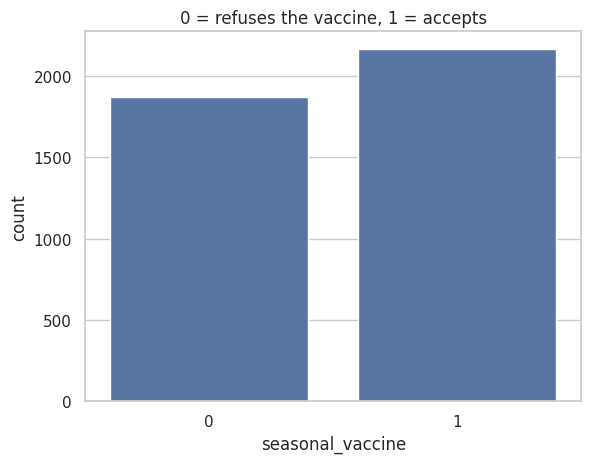

In [5]:
# Is the target balanced?
print(train_df[TARGET].value_counts())
print()
print((train_df[TARGET].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

sns.countplot(x=TARGET, data=train_df)
plt.title('0 = refuses the vaccine, 1 = accepts')
plt.show()

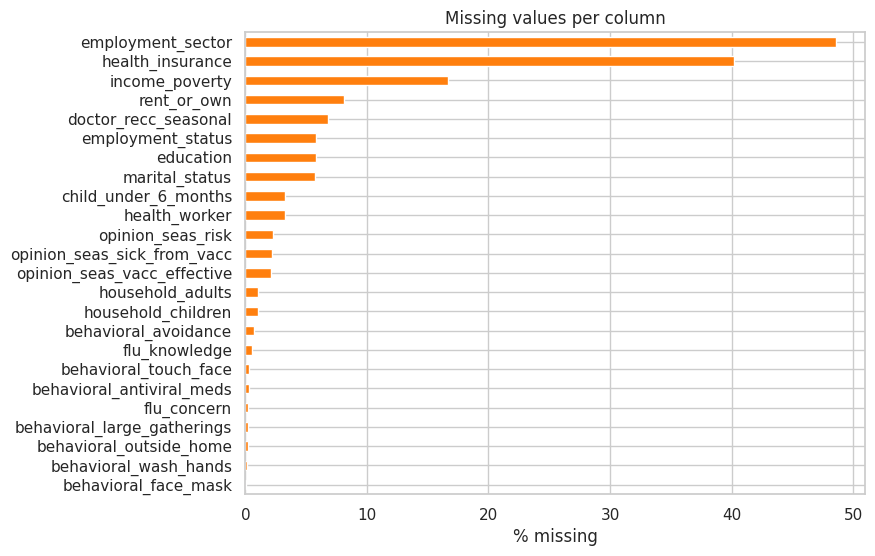

,0
employment_sector,48.6
health_insurance,40.2
income_poverty,16.7
rent_or_own,8.1
doctor_recc_seasonal,6.8
employment_status,5.8
education,5.8
marital_status,5.7
child_under_6_months,3.3
health_worker,3.2


In [6]:
# How many values are missing in each column?
missing = (train_df.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

plt.figure(figsize=(8, 6))
missing.plot(kind='barh', color='tab:orange')
plt.xlabel('% missing')
plt.title('Missing values per column')
plt.gca().invert_yaxis()
plt.show()

missing.round(1)

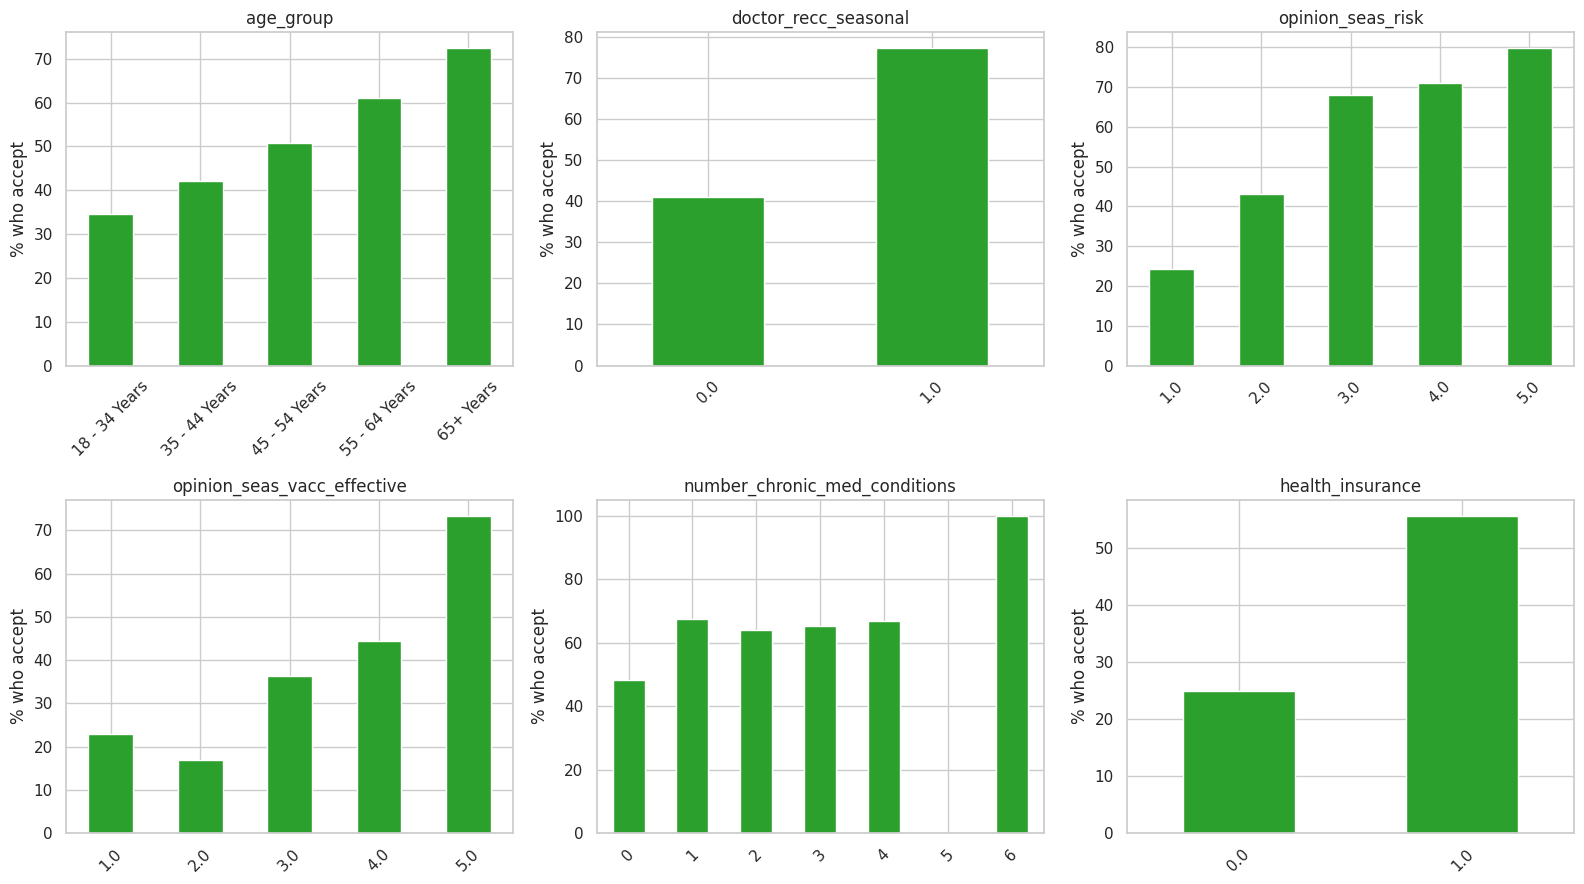

In [7]:
# Which groups accept the vaccine most often? (% who accept)
columns_to_check = ['age_group', 'doctor_recc_seasonal', 'opinion_seas_risk',
                    'opinion_seas_vacc_effective', 'number_chronic_med_conditions', 'health_insurance']

fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axs.flatten(), columns_to_check):
    # Missing values are filled with the MODE (most common value) - only for this chart.
    # The real imputation for the models (median / MICE) happens inside the pipeline in Step 4.
    filled = train_df[col].fillna(train_df[col].mode()[0])
    rate = train_df.groupby(filled.astype(str))[TARGET].mean() * 100
    rate.plot(kind='bar', ax=ax, color='tab:green')
    ax.set_title(col)
    ax.set_ylabel('% who accept')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# ====== CHANGE THESE NUMBERS TO YOUR TEAM'S AI ESTIMATES ======
VACCINE_COST = 300          # $ per vaccine (from the dataset information)
HOSPITAL_COST = 18500       # $ per hospitalisation (from the dataset information)

BASE_RISK = {               # unvaccinated, 0 chronic conditions
    '18 - 34 Years': 0.002,
    '35 - 44 Years': 0.003,
    '45 - 54 Years': 0.005,
    '55 - 64 Years': 0.010,
    '65+ Years':     0.030,
}
CHRONIC_FACTOR = {0: 1, 1: 2, 2: 3, 3: 4}   # 3 = "3 or more"
VACCINE_EFFECT = 0.35                       # vaccine lowers the hospital risk by 35%
# ==============================================================

# Show the full table
rows = []
for age, base in BASE_RISK.items():
    for n_chronic, factor in CHRONIC_FACTOR.items():
        p_unvacc = min(base * factor, 1.0)
        p_vacc = p_unvacc * (1 - VACCINE_EFFECT)
        rows.append({'Age group': age, 'Chronic conditions': f"{n_chronic}{'+' if n_chronic == 3 else ''}",
                     'P(hospital) unvaccinated': p_unvacc, 'P(hospital) vaccinated': p_vacc,
                     '$ saved if vaccinated': (p_unvacc - p_vacc) * HOSPITAL_COST})
risk_table = pd.DataFrame(rows)
risk_table.round(4)

,Age group,Chronic conditions,P(hospital) unvaccinated,P(hospital) vaccinated,$ saved if vaccinated
0,18 - 34 Years,0,0.002,0.0013,12.950
1,18 - 34 Years,1,0.004,0.0026,25.900
2,18 - 34 Years,2,0.006,0.0039,38.850
3,18 - 34 Years,3+,0.008,0.0052,51.800
4,35 - 44 Years,0,0.003,0.0020,19.425
5,35 - 44 Years,1,0.006,0.0039,38.850
6,35 - 44 Years,2,0.009,0.0059,58.275
7,35 - 44 Years,3+,0.012,0.0078,77.700
8,45 - 54 Years,0,0.005,0.0032,32.375
9,45 - 54 Years,1,0.010,0.0065,64.750


In [10]:
def hospital_probabilities(X):
    """For every person in X: (P(hospital) if unvaccinated, P(hospital) if vaccinated)."""
    base = X['age_group'].map(BASE_RISK).values
    n_chronic = X['number_chronic_med_conditions'].clip(upper=3).values
    factor = pd.Series(n_chronic).map(CHRONIC_FACTOR).values
    p_unvacc = np.minimum(base * factor, 1.0)
    p_vacc = p_unvacc * (1 - VACCINE_EFFECT)
    return p_unvacc, p_vacc

In [11]:
def town_costs(accepts, send, p_unvacc, p_vacc):
    """Cost in $ for every person.
    accepts = 1 if the person really accepts the vaccine, send = 1 if we send one."""
    accepts = np.asarray(accepts)
    send = np.asarray(send)
    # $300 is paid if we send a vaccine OR if the person wanted one (the law pays them instead)
    vaccine_cost = VACCINE_COST * ((send == 1) | (accepts == 1))
    # the person is only protected if we sent the vaccine AND they accepted it
    vaccinated = (send == 1) & (accepts == 1)
    hospital_cost = HOSPITAL_COST * np.where(vaccinated, p_vacc, p_unvacc)
    return vaccine_cost + hospital_cost


def average_cost(accepts, send, X):
    p_unvacc, p_vacc = hospital_probabilities(X)
    return town_costs(accepts, send, p_unvacc, p_vacc).mean()

In [12]:
def decide_send(q, X):
    """q = predicted probability that each person accepts. Returns 1 = send, 0 = don't send."""
    p_unvacc, p_vacc = hospital_probabilities(X)
    benefit_if_sent = q * (p_unvacc - p_vacc) * HOSPITAL_COST
    waste_if_sent = (1 - q) * VACCINE_COST
    return (benefit_if_sent > waste_if_sent).astype(int)


def cost_scorer(model, X, y):
    """Scorer for scikit-learn: NEGATIVE average cost (scikit-learn always maximises scores)."""
    q = model.predict_proba(X)[:, 1]
    return -average_cost(y, decide_send(q, X), X)


# Example: the same 60% chance of accepting, but different people
example = pd.DataFrame({'age_group': ['18 - 34 Years', '65+ Years', '65+ Years'],
                        'number_chronic_med_conditions': [0, 0, 2]})
print("Decision for q = 0.6:", decide_send(np.array([0.6, 0.6, 0.6]), example), "(1 = send)")

Decision for q = 0.6: [0 0 1] (1 = send)


In [13]:
y_all = train_df[TARGET].values
n = len(train_df)
baselines = {
    'Send to nobody': average_cost(y_all, np.zeros(n), train_df),
    'Send to everybody': average_cost(y_all, np.ones(n), train_df),
    'Perfect knowledge (impossible best)': average_cost(y_all, y_all, train_df),
}
pd.Series(baselines, name='Average cost per person ($)').round(2)

,Average cost per person ($)
Send to nobody,471.15
Send to everybody,535.88
Perfect knowledge (impossible best),396.79
